<a href="https://colab.research.google.com/github/samkenzie/predicting-electrode-transport-properties/blob/main/Baseline1_Bruggeman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baseline Model 1: Bruggeman Relation

The Bruggeman relation estimates tortuosity (how much the path of an ion travelling through the electrode deviates from straight) from electrode porosity. Then, the effective diffusivity and conductivity will be calculated using the ratio of porosity to tortuosity.

The procedure for this baseline model is as follows:
1. Import image data
2. Obtain porosity from image sample (ratio of white (1) vs. black (0) pixels in the 64x64 image)
3. Import effective diffusivity and conductivity, order to match image data
4. Finding coefficient relating tortuosity and porosity for this dataset
5. Computing R^2 of this model

*Note that the Bruggeman model assumes isotropic sperical particles (as discussed in my progress report), which the particles in this computer-generated dataset are not, thus deep learning proves a better alternative logically.

In [29]:
#0. Imports
import numpy as np
from pathlib import Path
import glob
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

In [2]:
#1. Import image data
!unzip -q /content/images_aps360.zip -d /content/images
!unzip -q /content/diffusion_aps360.zip -d /content/texts

In [4]:
img_ids, img_pixels = [], []
for path in glob.glob("/content/images/64/*.tif"):
    img_ids.append(int(Path(path).stem)) #123.tif -> 123
    img_pixels.append(np.array(Image.open(path).convert("L"), dtype=np.uint8))

img_ids = np.array(img_ids)
img_pixels = np.stack(img_pixels) #Expected (100000, 64, 64)

print(f"Loaded {len(img_ids)} images")
print(f"Array shape {img_pixels.shape}")

Loaded 100000 images
Array shape (100000, 64, 64)


The images are black and white, thus pixel values (numerically) are 0 and 255 respectively.

In [5]:
#2. Obtain porosity
porosity = []

for img in img_pixels: #ie. for one 64x64 image
    num_white = (img == 255).sum() #Sum of pixels that =255 (aka. white)
    porosity.append(num_white / img.size) #img.size = 64*64 = 4096

porosity = np.array(porosity)

print(f"Calculated {len(porosity)} porosities")
print(f"Range: {porosity.min():.3f} to {porosity.max():.3f}, mean {porosity.mean():.3f}, median {np.median(porosity):.3f}")

Calculated 100000 porosities
Range: 0.153 to 0.898, mean 0.492, median 0.491


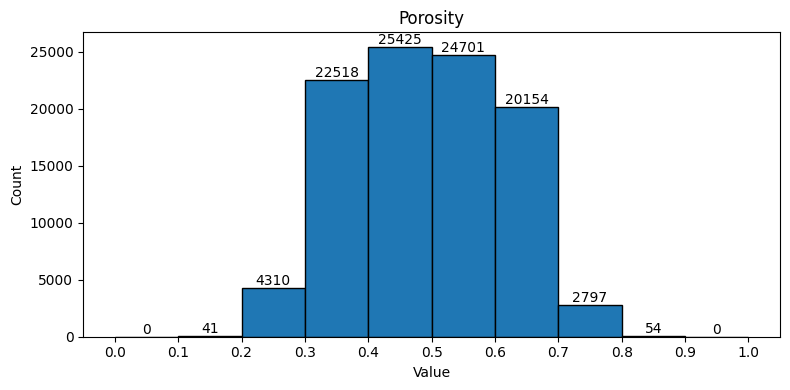

In [6]:
bins = np.linspace(0, 1, 11)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(porosity, bins=bins, edgecolor="black")
ax.set_title("Porosity")
ax.set_xlabel("Value")
ax.set_ylabel("Count")
ax.set_xticks(bins)
ax.bar_label(ax.containers[0])
plt.tight_layout() #Removes extra text generated

In [8]:
#3. Import effective diffusivity and conductivity data
txt_ids, eff_diff, eff_cond = [], [], []

for path in glob.glob("/content/texts/dispersion/*.txt"):
    with open(path) as fh:
        vals = fh.read().split()
        txt_ids.append(int(Path(path).stem))
        eff_diff.append(float(vals[0]))
        eff_cond.append(float(vals[1]))

print(f"Loaded {len(txt_ids)} text files")

Loaded 100000 text files


In [9]:
#3. CONT. Ordering targets to match image data order
order = {id_: i for i, id_ in enumerate(txt_ids)}
id = [order[i] for i in img_ids]
eff_diff = np.array(eff_diff)[id]
eff_cond = np.array(eff_cond)[id]

In [43]:
txt_ids_aligned = np.array(txt_ids)[id] #Grabbing .txt IDs

print("img_id  txt_id")
for i in range(10): #Checking if the first 10 image and text file IDs match
    print(f"{img_ids[i]:6d} {txt_ids_aligned[i]:6d}")

print(np.all(img_ids == txt_ids_aligned)) #True if all IDs match

img_id  txt_id
 21534  21534
 36886  36886
 99674  99674
 79219  79219
 29446  29446
 82103  82103
 37870  37870
 94266  94266
 69290  69290
 44433  44433
True


In [37]:
#4.1 Finding coefficient relating porosity and effective diffusivity
alpha, c1 = np.polyfit(np.log(porosity), np.log(eff_diff), 1) #Uses least squares to fit a line (alpha=Bruggeman exponent relation, c1=constant)
print(f"Alpha = {alpha:.2f}")

Alpha = 1.62


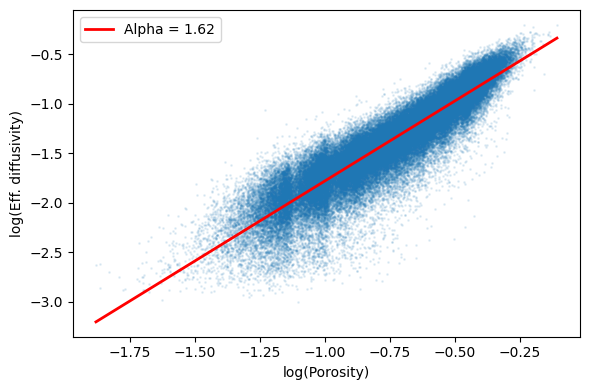

In [27]:
x = np.linspace(porosity.min(), porosity.max(), 200)
y = np.exp(c1) * (x ** alpha)

plt.figure(figsize=(6, 4))
plt.scatter(np.log(porosity), np.log(eff_diff), s=1, alpha=0.1)
plt.plot(np.log(x), np.log(y), color="red", linewidth=2, label=f"Alpha = {alpha:.2f}")
plt.xlabel("log(Porosity)")
plt.ylabel("log(Eff. diffusivity)")
plt.legend()
plt.tight_layout() #Removes extra text generated

In [33]:
#4.2 Finding coefficient relating porosity and effective conductivity
beta, c2 = np.polyfit(np.log(porosity), np.log(eff_cond), 1) #Uses least squares to fit a line (beta=Bruggeman exponent relation, c2=constant)
print(f"Beta = {beta:.2f}")

Beta = 1.60


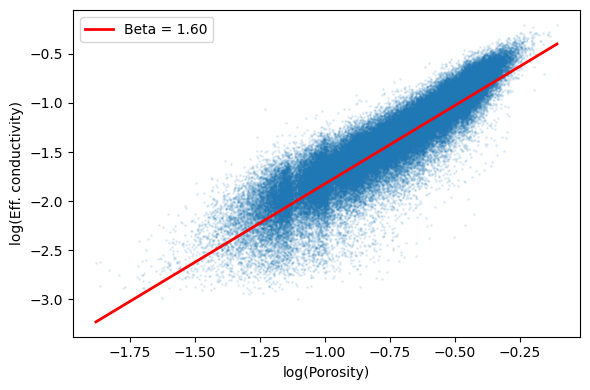

In [44]:
x = np.linspace(porosity.min(), porosity.max(), 200)
y = np.exp(c2) * (x ** beta)

plt.figure(figsize=(6, 4))
plt.scatter(np.log(porosity), np.log(eff_diff), s=1, alpha=0.1)
plt.plot(np.log(x), np.log(y), color="red", linewidth=2, label=f"Beta = {beta:.2f}")
plt.xlabel("log(Porosity)")
plt.ylabel("log(Eff. conductivity)")
plt.legend()
plt.tight_layout() #Removes extra text generated

In [38]:
#5.1 Computing R^2 for effective diffusivity prediction
pred1 = np.exp(c1) * (porosity ** alpha)
print("Bruggeman R^2:", r2_score(eff_diff, pred1))

Bruggeman R^2: 0.8587882998578873


In [35]:
#5.2 Computing R^2 for effective conductivity prediction
pred2 = np.exp(c2) * (porosity ** beta)
print("Bruggeman R^2:", r2_score(eff_cond, pred2))

Bruggeman R^2: 0.8492314102125578
